# Moskitto Radar · Previsão de risco de roubo

**GS CitizenTech FIAP 2026.2 · Inteligência Artificial & Machine Learning**
Gabriel Couto (RM559579) · equipe: Gabriel Kato (RM560000), João Vitor de Matos (RM559246), Marcelo Affonso (RM559790)

## 1. Problema

Quem mora ou circula pela Região Metropolitana de São Paulo não tem um jeito simples de saber **onde e quando o risco
de roubo é maior**. O Moskitto Radar mostra isso no app. Este notebook treina o modelo que faz essa previsão:

O modelo responde duas perguntas:

1. **Onde e quando o risco é maior?** Dado o histórico de um lugar, qual será o **nível de risco (baixo, médio ou
   alto)** de cada faixa horária no período seguinte? O resultado vira o `previsoes.json`, que a API serve em
   `GET /api/previsoes` e o app pinta no mapa e na aba Risco (seções 4 a 7).
2. **Quantos roubos esperar agora, se a SSP ainda não publicou?** A SSP publica com cerca de 3 meses de atraso. O
   modelo prevê os meses que faltam, e os relatos dos moradores corrigem a previsão na hora (seção 8). É aqui que
   os relatos do app mudam o resultado.

In [1]:
import json
import sys
from datetime import date
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PASTA_IA = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PASTA_IA))
DADOS = PASTA_IA / "data"

from risco import estilo, figuras
from risco.modelo import (CHAVE, avaliar, features, janelas, limites, previsoes, probabilidades,
                          referencias, rotular, taxas, treinar)

estilo.aplicar()
pd.set_option("display.precision", 3)

def mostrar(fig, nome):
    caminho = estilo.salvar(fig, nome)
    import matplotlib.pyplot as plt
    plt.close(fig)
    display(Image(filename=str(caminho), width=900))

## 2. Dados e origem

- **Roubos reais:** bases públicas **Celulares Subtraídos** e **Veículos Subtraídos** da Secretaria da Segurança
  Pública de SP (portal de estatística → Bases de Dados), anos 2024, 2025 e 2026. Uma linha por pessoa, natureza ou
  objeto citado no BO. A própria SSP avisa que a base é **bruta e não é estatística oficial**.
- **Lugares:** os 129 lugares do app (3 bairros da Av. Paulista, 88 distritos da capital, 38 municípios),
  com nomes e códigos do IBGE e centros do IBGE e do OpenStreetMap.
- **Privacidade:** as planilhas brutas (com endereço, CEP e placa) **ficam fora do repositório**. O script
  `scripts/extrair_ssp.py` lê as planilhas e grava só **contagens por lugar, dia e faixa horária**.

Limpeza feita pelo script (detalhes no README):
1. só BOs de **roubo** (art. 157), sem furto nem perda;
2. só a **Região Metropolitana** (código IBGE do município);
3. cada BO conta **uma vez** (delegacia + ano + número), mesmo aparecendo nas duas bases;
4. faixa horária pela **hora** do fato ou, sem ela, pelo **período** do BO;
5. na capital, o lugar é o **centro de distrito mais próximo** da coordenada; fora dela, o próprio município.

In [2]:
resumo = json.loads((DADOS / "extracao_resumo.json").read_text())
lugares = pd.read_csv(DADOS / "lugares.csv")
agregado = pd.read_csv(DADOS / "roubos_agregados.csv", parse_dates=["data"])
por_hora = pd.read_csv(DADOS / "roubos_por_hora.csv")
fim = date.fromisoformat(resumo["periodo"]["fim"])
print(f"Período: {resumo['periodo']['inicio']} a {resumo['periodo']['fim']}")
print(f"Roubos por ano: {resumo['por_ano']}")
print(f"Lugares: {len(lugares)} ({lugares.tipo.value_counts().to_dict()})")
agregado.head()

Período: 2024-01-01 a 2026-08-31
Roubos por ano: {'2024': 102617, '2025': 86575, '2026': 49896}
Lugares: 129 ({'distrito': 88, 'municipio': 38, 'bairro': 3})


,bairro,data,faixa_horaria,roubos,roubos_celular,roubos_veiculo
0,bela_vista,2024-01-01,madrugada,4,4,0
1,bela_vista,2024-01-03,noite,1,1,0
2,bela_vista,2024-01-05,madrugada,1,1,0
3,bela_vista,2024-01-05,tarde,1,1,0
4,bela_vista,2024-01-06,noite,2,2,0


findfont: Failed to find font weight bold for Noto Sans, now using 400.


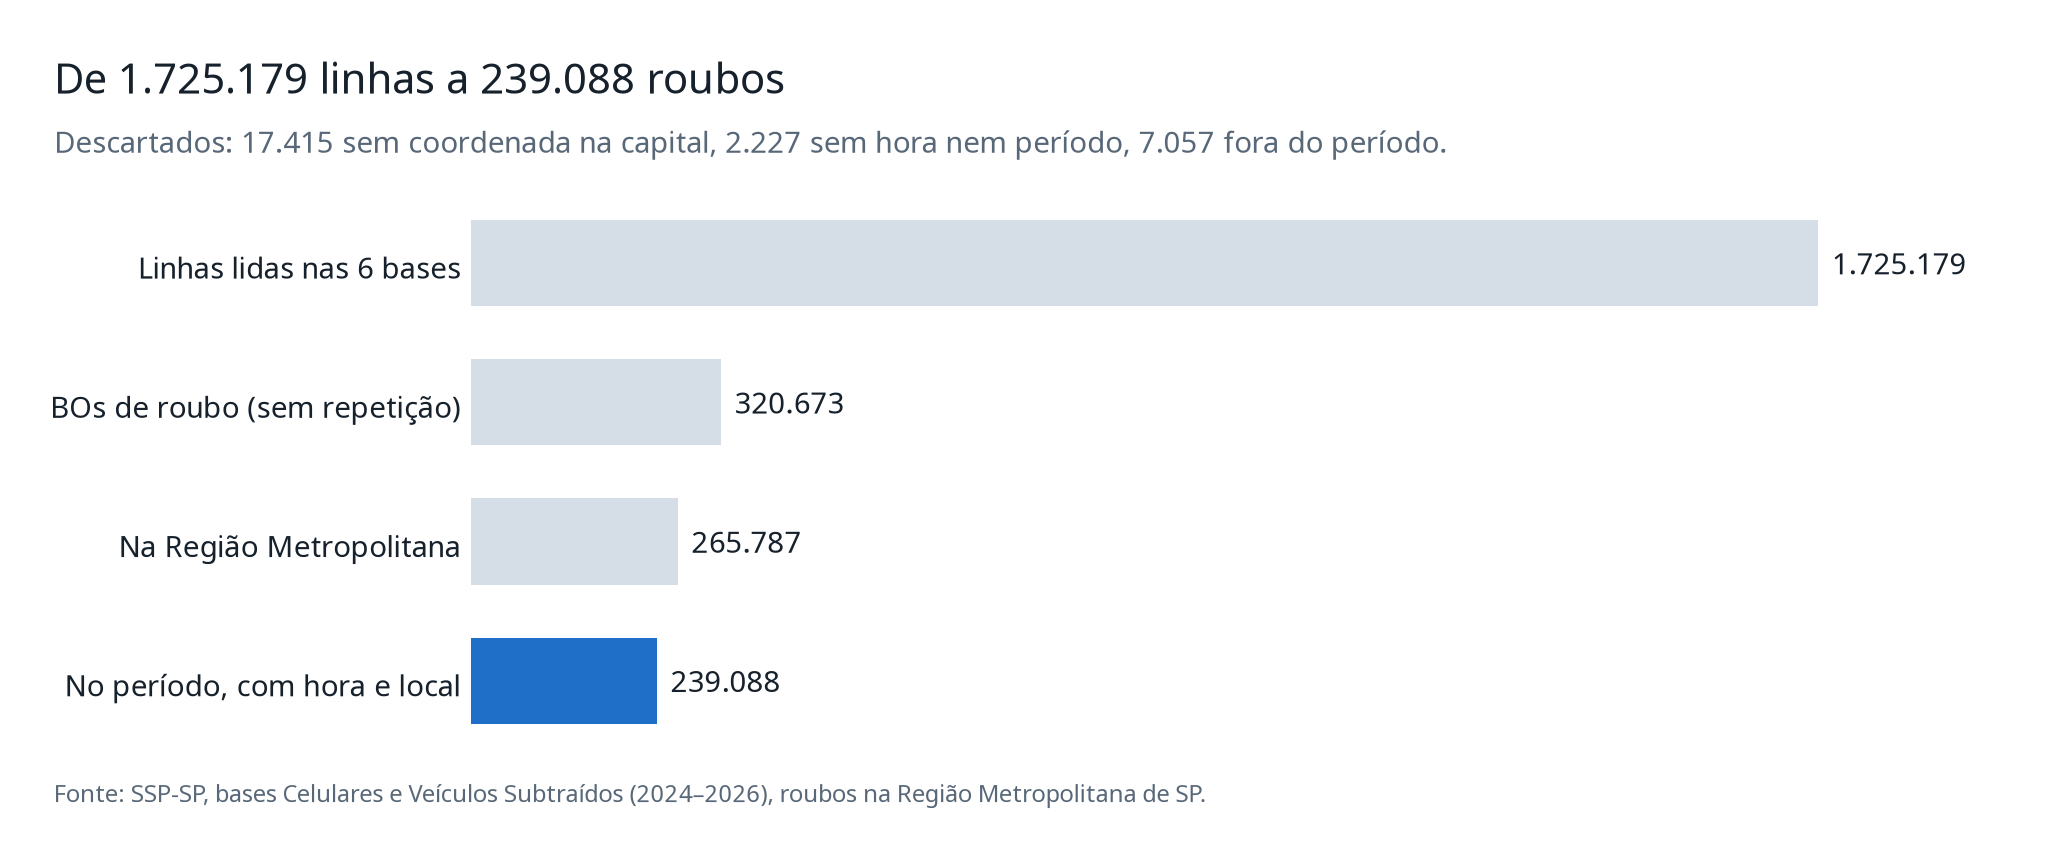

In [3]:
mostrar(figuras.funil(resumo), "01_funil")

## 3. Análise exploratória

Antes de modelar, o que os dados dizem sobre **quando** e **onde** os roubos acontecem.

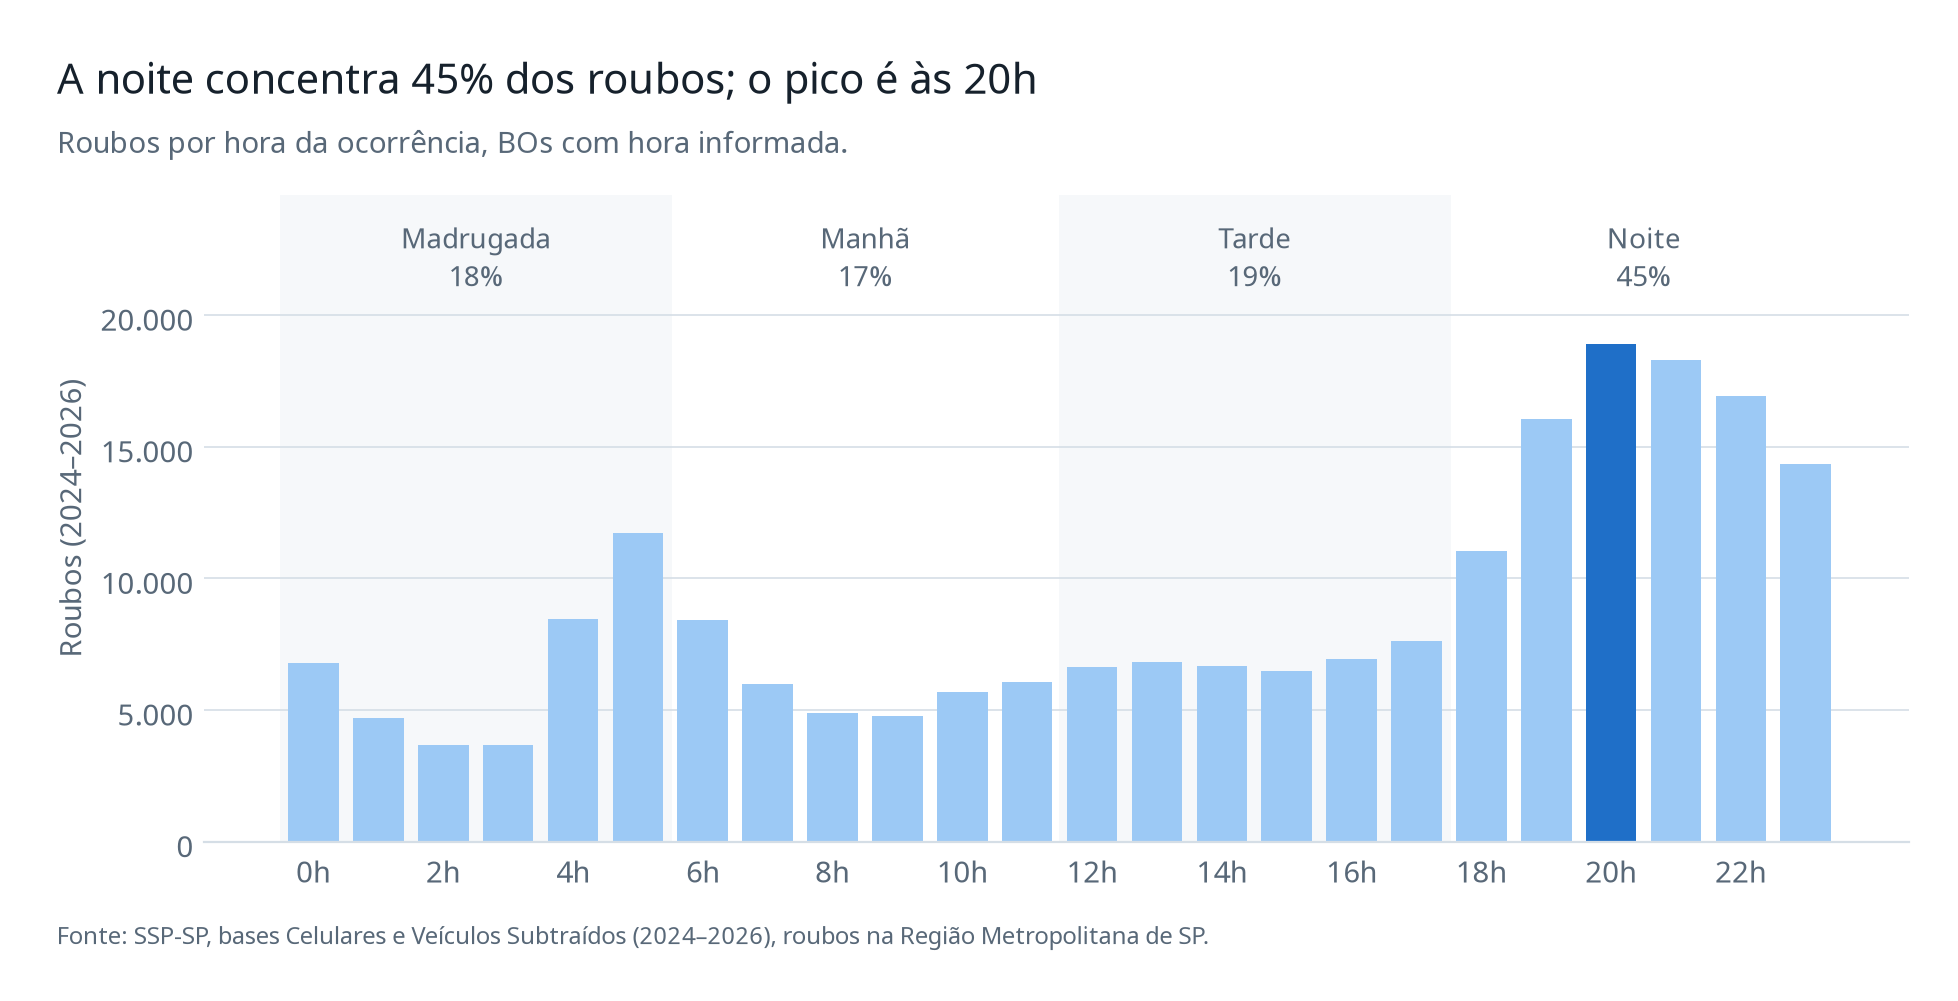

In [4]:
mostrar(figuras.relogio(por_hora), "02_relogio")

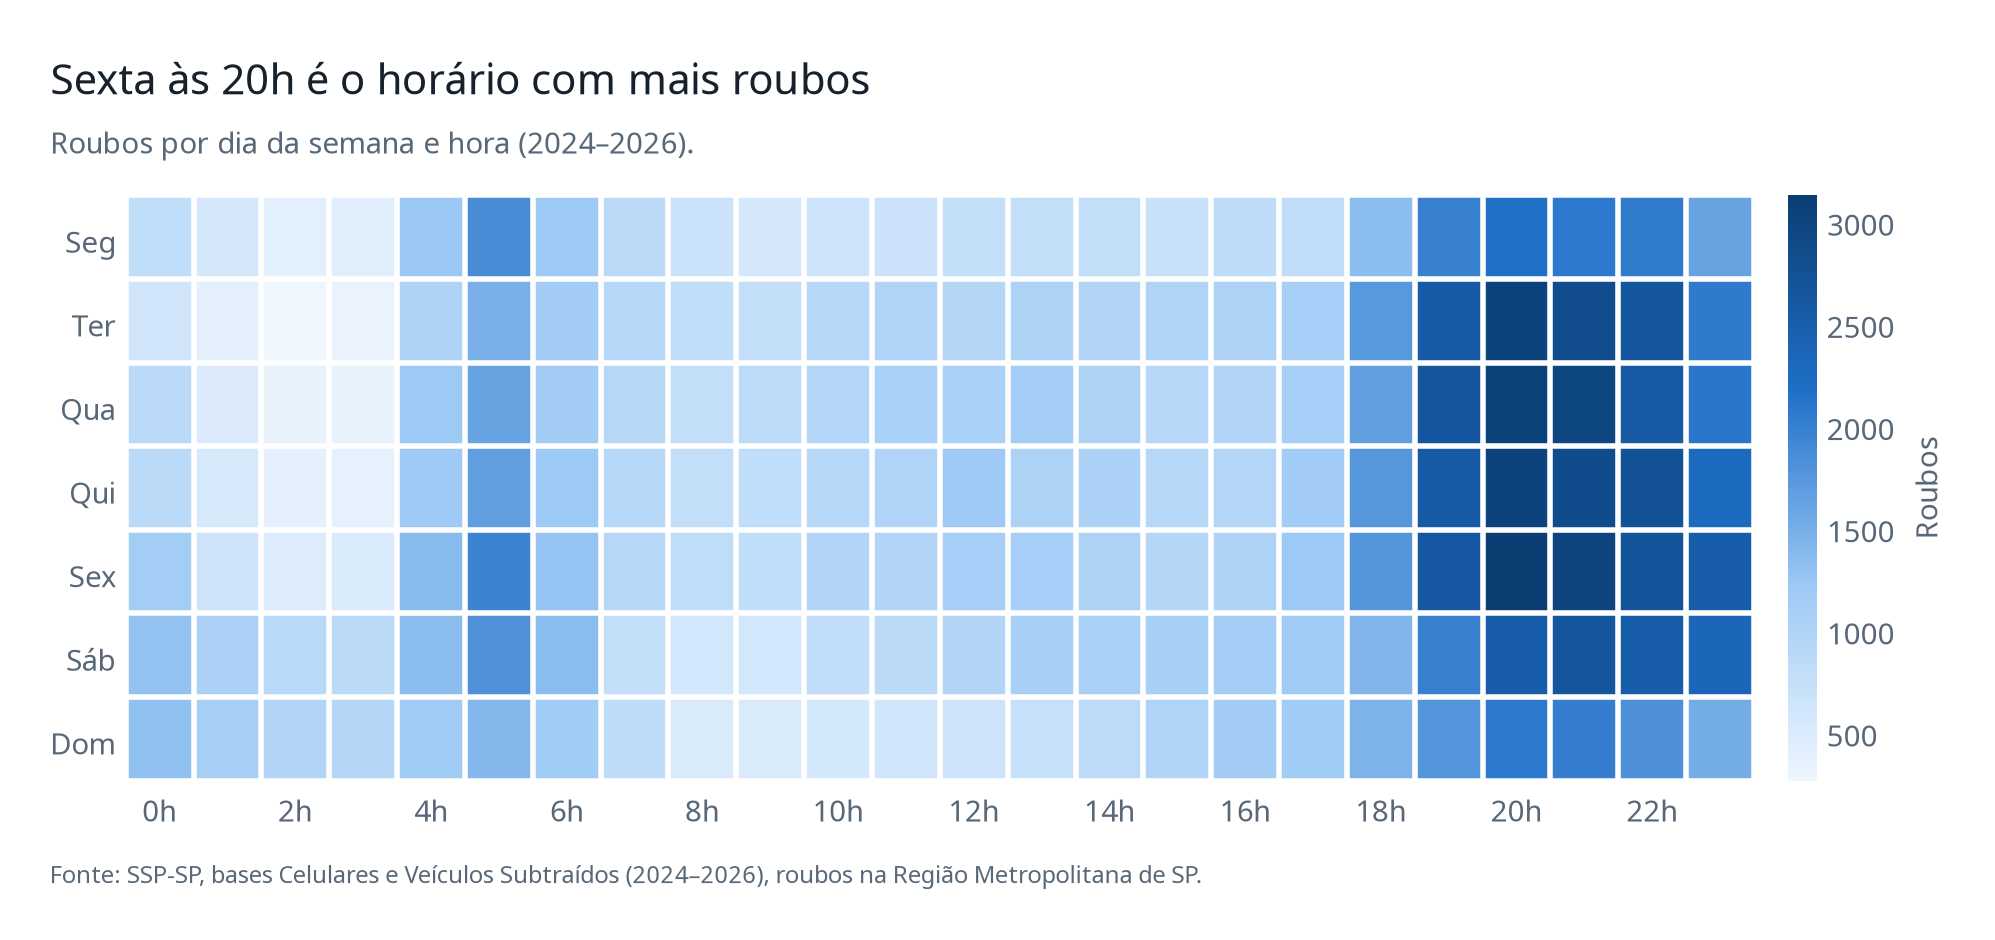

In [5]:
mostrar(figuras.calendario(por_hora), "03_calendario")

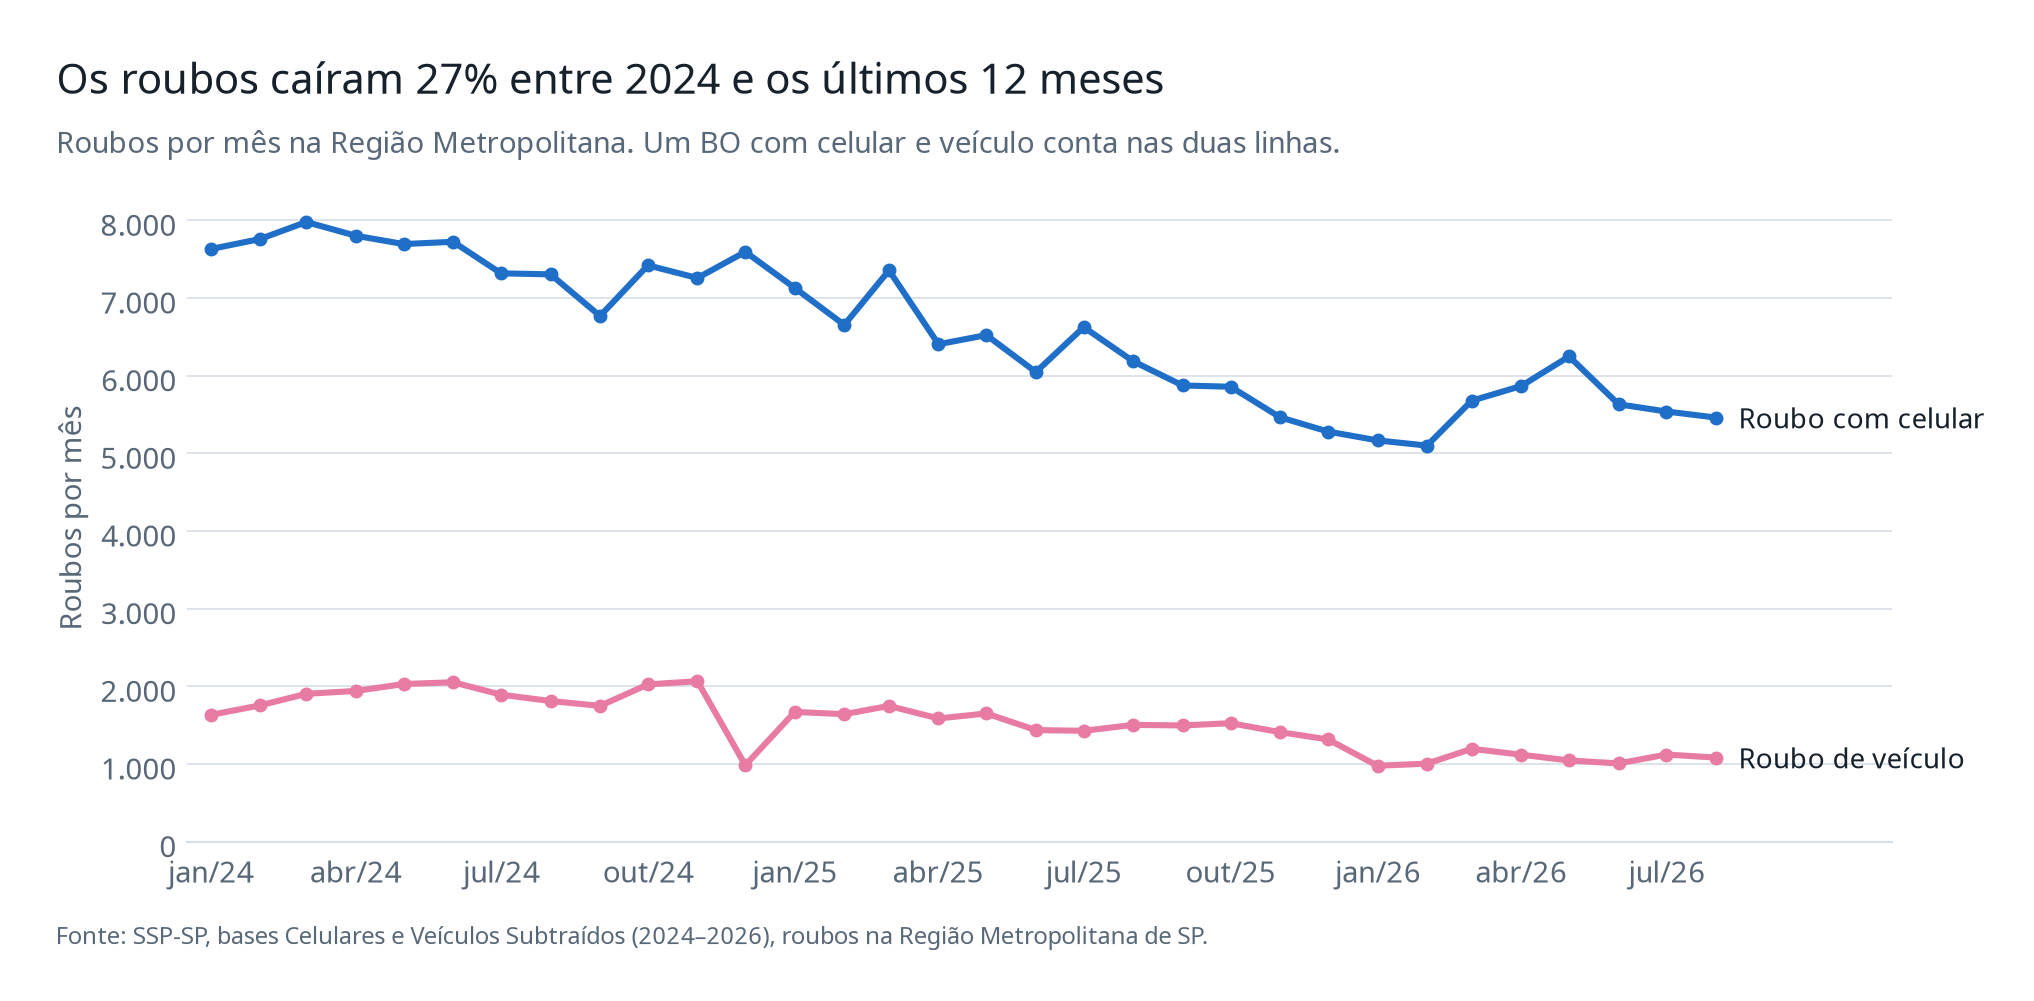

In [6]:
mensal = (agregado.assign(mes=agregado.data.dt.to_period("M").dt.to_timestamp())
          .groupby("mes")[["roubos_celular", "roubos_veiculo"]].sum()
          .rename(columns={"roubos_celular": "celular", "roubos_veiculo": "veiculo"}).reset_index())
mostrar(figuras.serie_mensal(mensal), "04_serie_mensal")

In [7]:
por_lugar = (agregado.groupby("bairro").roubos.sum().rename("roubos").reset_index()
             .merge(lugares, left_on="bairro", right_on="codigo"))
print("Lugares com mais roubos (2024–2026):")
por_lugar.nlargest(10, "roubos")[["nome", "tipo", "roubos"]].reset_index(drop=True)

Lugares com mais roubos (2024–2026):


,nome,tipo,roubos
0,Santo André,municipio,9857
1,Guarulhos,municipio,9182
2,Capão Redondo,distrito,7731
3,São Bernardo do Campo,municipio,7540
4,República,distrito,5893
5,Osasco,municipio,5709
6,Campo Limpo,distrito,5523
7,Diadema,municipio,4611
8,Pinheiros,distrito,4156
9,Carapicuíba,municipio,4073


## 4. Preparação

**Célula** = lugar × faixa horária × tipo de dia (útil ou fim de semana): 129 × 4 × 2 = **1.032 células**.
**Taxa** = roubos da célula ÷ número de dias daquele tipo no período.

**Regra do `nivel_risco`** (o rótulo): com as taxas do ano usado como rótulo do treino (2025),
- **baixo** até o percentil 50 das células,
- **médio** do percentil 50 ao 80,
- **alto** acima do percentil 80.

Os mesmos limites rotulam o teste. Assim, "alto" quer dizer "entre os 20% de lugar e horário com mais roubos por dia".

**Janelas (teste por tempo, sem vazamento):** as features vêm só do ano anterior ao rótulo.

| | Features (histórico) | Rótulo (o que se prevê) |
|---|---|---|
| Treino | 2024 | 2025 |
| Teste | 2025 | 2026 (até o último mês completo) |
| Previsão final | últimos 12 meses | próximo período |

In [8]:
j = janelas(fim)
taxa_treino = taxas(agregado, lugares, *j["treino_y"]).set_index(CHAVE).taxa
lim = limites(taxa_treino)
print(f"Limites (roubos por dia na célula): médio > {lim[0]:.3f}, alto > {lim[1]:.3f}")

y_treino = rotular(taxa_treino, lim)
y_teste = rotular(taxas(agregado, lugares, *j["teste_y"]).set_index(CHAVE).taxa, lim)
y_anterior = rotular(taxas(agregado, lugares, *j["teste_x"]).set_index(CHAVE).taxa, lim)
x_treino = features(agregado, lugares, *j["treino_x"])
x_teste = features(agregado, lugares, *j["teste_x"])
y_treino, y_teste, y_anterior = y_treino.loc[x_treino.index], y_teste.loc[x_teste.index], y_anterior.loc[x_teste.index]

pd.DataFrame({"treino (2025)": y_treino.value_counts(), "teste (2026)": y_teste.value_counts()}).loc[["baixo", "medio", "alto"]]

Limites (roubos por dia na célula): médio > 0.297, alto > 0.674


,treino (2025),teste (2026)
baixo,516,557
medio,309,310
alto,207,165


In [9]:
x_treino.head()

taxa_celula  taxa_lugar  \
bairro     faixa_horaria fim_de_semana                            
bela_vista madrugada     0                    0.229       2.022   
                         1                    0.702       2.022   
           manha         0                    0.328       2.022   
                         1                    0.260       2.022   
           tarde         0                    0.344       2.022   

                                        participacao_faixa  fracao_veiculo  \
bairro     faixa_horaria fim_de_semana                                       
bela_vista madrugada     0                           0.180           0.009   
                         1                           0.180           0.009   
           manha         0                           0.153           0.009   
                         1                           0.153           0.009   
           tarde         0                           0.224           0.009   

                                        tipo_bairro  tipo_distrito  \
bairro     faixa_horaria fim_de_semana                               
bela_vista madrugada     0                        1              0   
                         1                        1              0   
           manha         0                        1              0   
                         1                        1              0   
           tarde         0                        1              0   

                                        tipo_municipio  dist_se_km  \
bairro     faixa_horaria fim_de_semana                               
bela_vista madrugada     0                           0       2.346   
                         1                           0       2.346   
           manha         0                           0       2.346   
                         1                           0       2.346   
           tarde         0                           0       2.346   

                                        dist_paulista_km  faixa_codigo  \
bairro     faixa_horaria fim_de_semana                                   
bela_vista madrugada     0                         0.286             0   
                         1                         0.286             0   
           manha         0                         0.286             1   
                         1                         0.286             1   
           tarde         0                         0.286             2   

                                        fim_de_semana  
bairro     faixa_horaria fim_de_semana                 
bela_vista madrugada     0                          0  
                         1                          1  
           manha         0                          0  
                         1                          1  
           tarde         0                          0

## 5. Modelo

- **Referência 1:** sempre a classe mais comum.
- **Referência 2 (a difícil):** o nível do ano anterior se repete. Se o modelo não superar isto, ele não acrescenta nada.
- **RandomForestClassifier** com classes balanceadas e busca de hiperparâmetros por validação cruzada
  (5 partes, F1 macro), só nos dados de treino.

In [10]:
modelo = treinar(x_treino, y_treino)
print("Melhores hiperparâmetros:", modelo.melhores_parametros_)
print(f"F1 macro na validação cruzada (treino): {modelo.f1_validacao_:.3f}")

Melhores hiperparâmetros: {'max_depth': 14, 'min_samples_leaf': 3, 'n_estimators': 400}
F1 macro na validação cruzada (treino): 0.844


## 6. Avaliação

Métrica principal: **F1 macro** (média do F1 das três classes), porque "alto" é a classe menor e a mais importante.
Também mostramos a acurácia e a matriz de confusão.

In [11]:
pred = modelo.predict(x_teste)
resultados = {"modelo": avaliar(y_teste, pred)}
for nome, p in referencias(y_treino, y_anterior).items():
    resultados[nome] = avaliar(y_teste, p)

pd.DataFrame({k: {"acurácia": v["acuracia"], "F1 macro": v["f1_macro"]} for k, v in resultados.items()}).T

,acurácia,F1 macro
modelo,0.842,0.819
classe_mais_comum,0.540,0.234
nivel_anterior,0.830,0.810


       precision  recall  f1-score  support
baixo      0.907   0.914     0.911    557.0
medio      0.746   0.719     0.732    310.0
alto       0.797   0.830     0.813    165.0


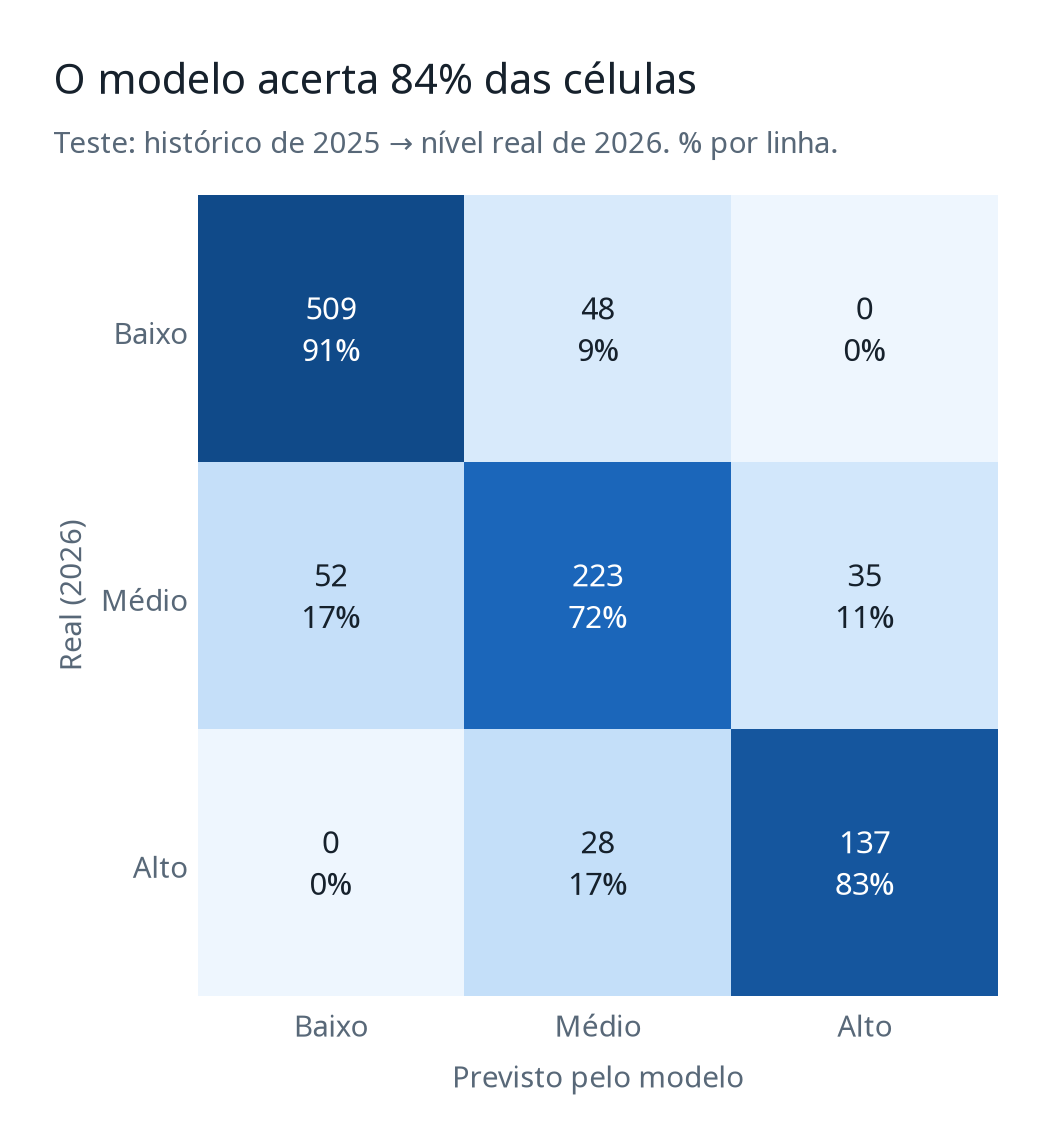

In [12]:
print(pd.DataFrame(resultados["modelo"]["relatorio"]).T.loc[["baixo", "medio", "alto"], ["precision", "recall", "f1-score", "support"]])
mostrar(figuras.matriz_confusao(resultados["modelo"]["matriz"]), "05_matriz_confusao")

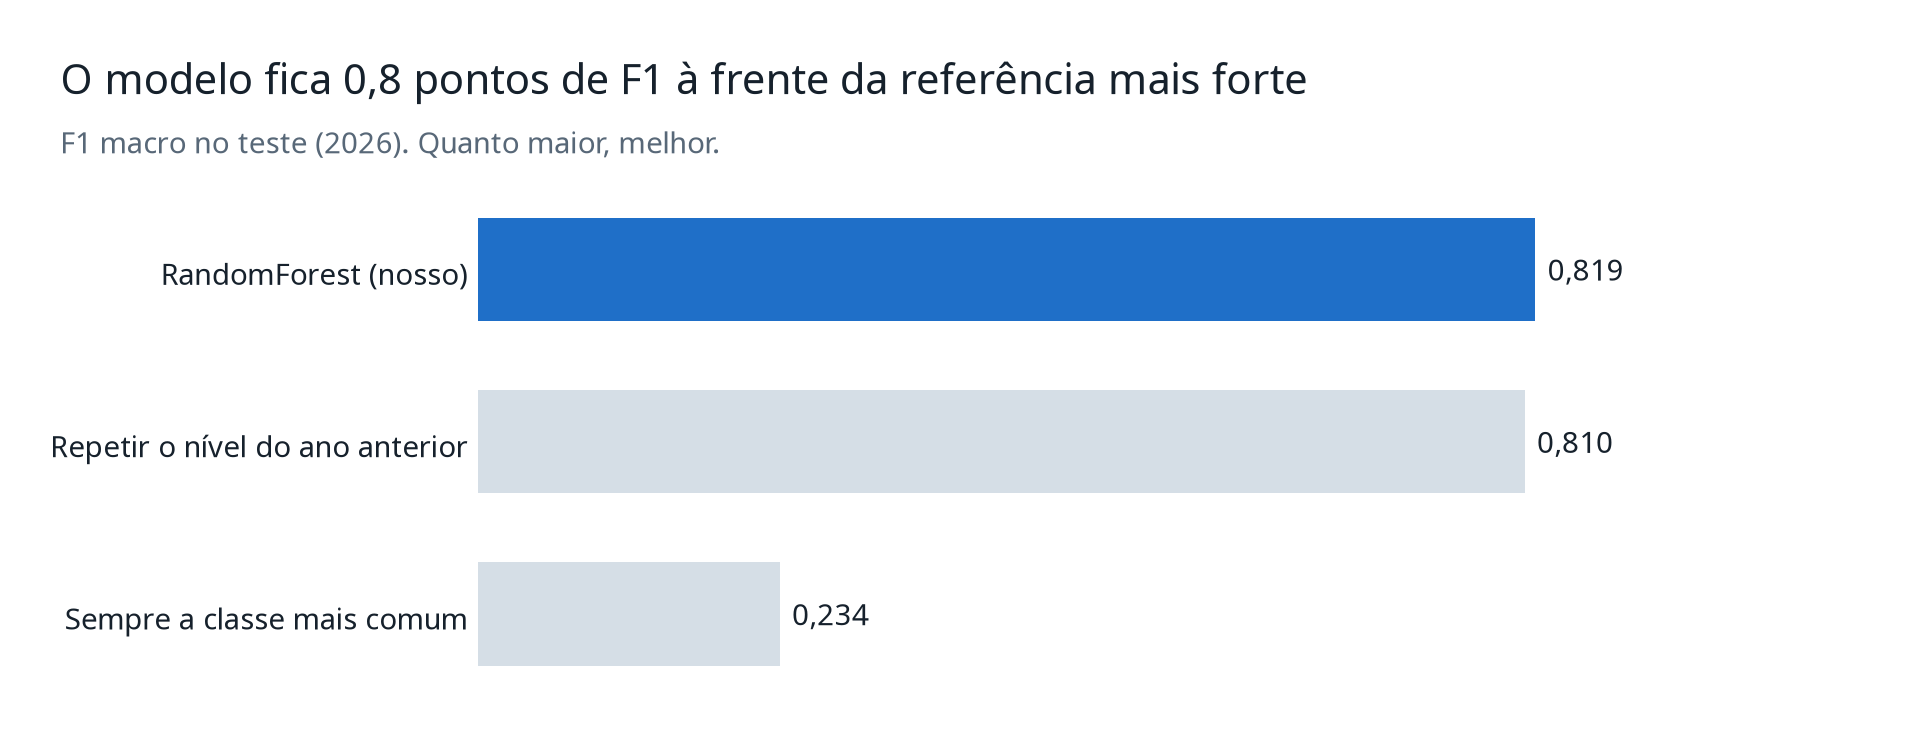

In [13]:
mostrar(figuras.comparacao_f1({k: v["f1_macro"] for k, v in resultados.items()}), "06_comparacao_f1")

**Leitura dos resultados.** O risco de um lugar muda pouco de um ano para o outro, por isso "repetir o nível do
ano anterior" já é uma referência forte. O RandomForest fica à frente dela e da classe mais comum, e erra quase
sempre para um nível vizinho (nunca confunde baixo com alto). Além do nível, ele dá a **probabilidade** de cada
classe, que vira o `score` mostrado no app; a referência não tem isso.

Testamos também a taxa dos últimos 3 meses e a média dos 5 lugares vizinhos como features: o F1 subiu menos de
0,005 (dentro do ruído), então ficamos com o modelo mais simples.

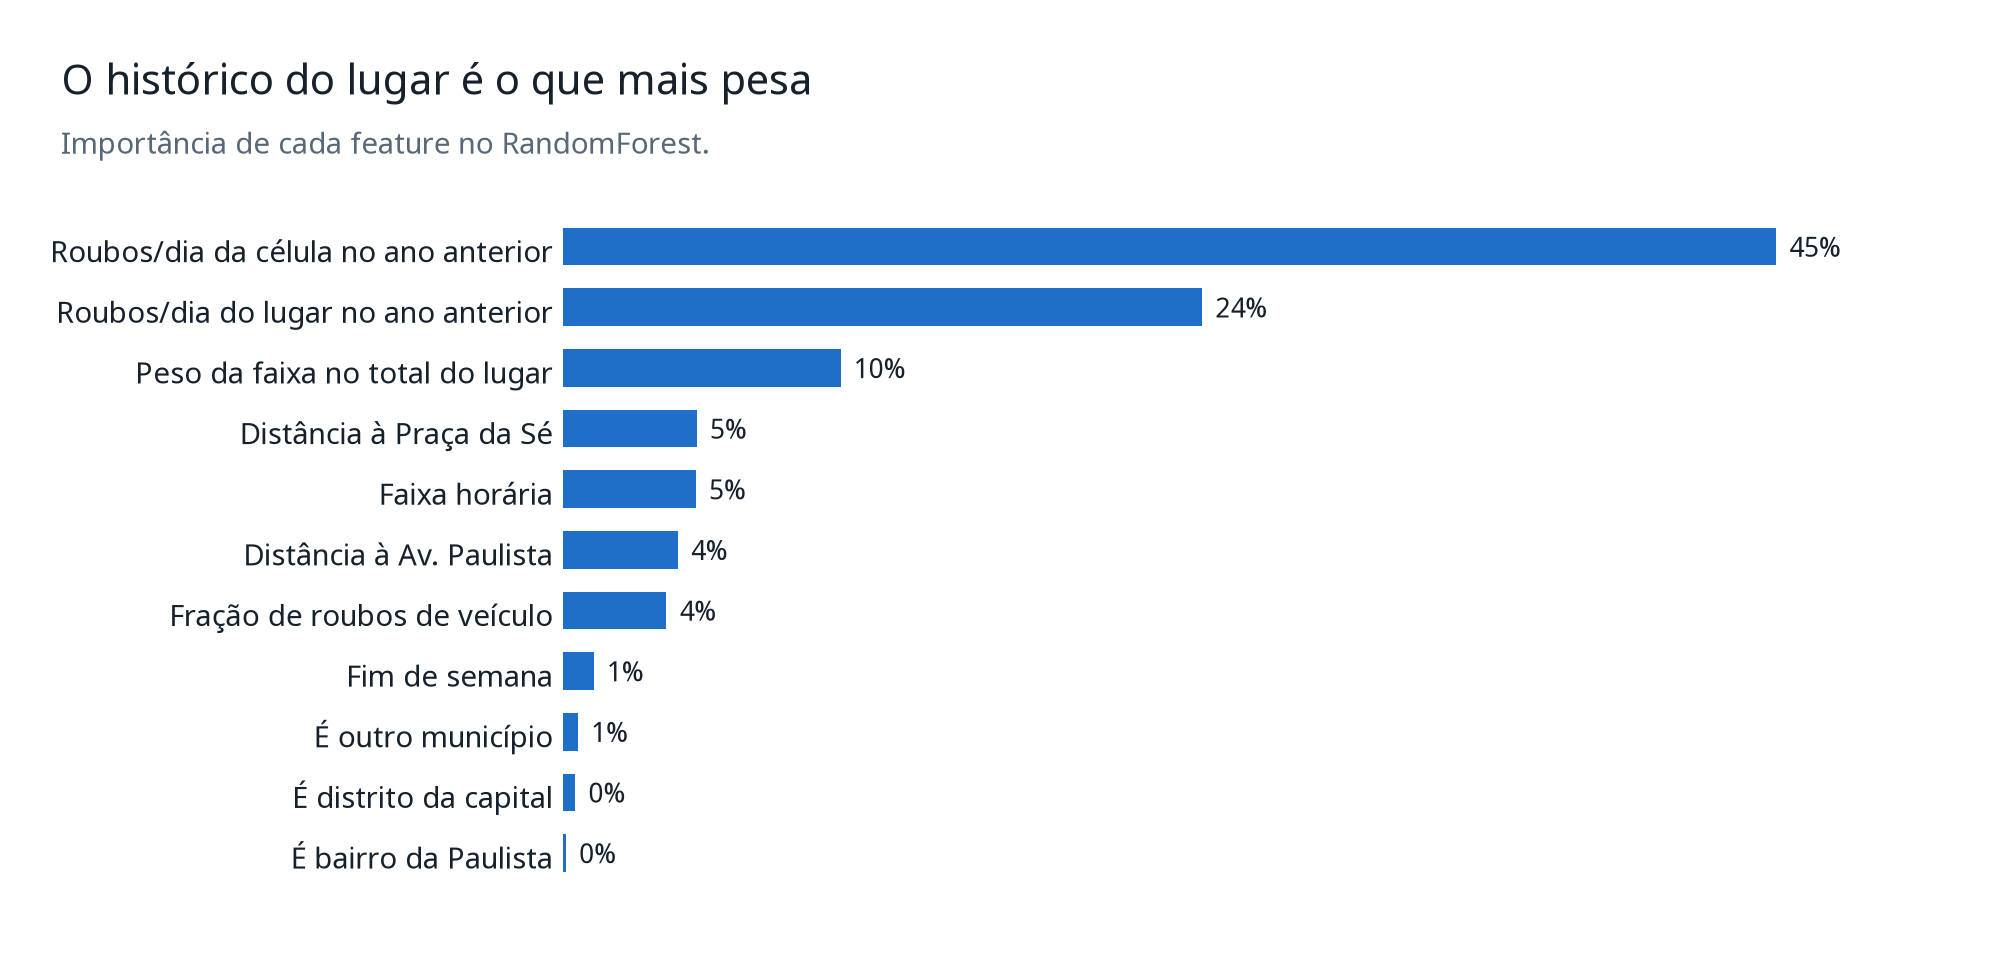

In [14]:
mostrar(figuras.importancia(list(x_treino.columns), list(modelo.feature_importances_)), "07_importancia")

## 7. Previsão e exportação

O modelo final é treinado de novo com o par mais recente (features de 2025 → rótulo de 2026) e prevê a partir
dos **últimos 12 meses**. Para cada lugar e faixa, as probabilidades de dia útil (peso 5/7) e de fim de semana
(peso 2/7) são juntadas.

- `nivel_risco` = nível mais provável;
- `score` = risco esperado (P(médio) × 0,5 + P(alto)), **preso à faixa do nível** (baixo 0,05–0,34, médio
  0,35–0,59, alto 0,60–0,95), os mesmos cortes que o app usa. Assim o mapa, a aba Risco e o detalhe nunca se contradizem.

In [15]:
import joblib

modelo_final = treinar(x_teste, y_teste)
x_final = features(agregado, lugares, *j["final_x"])
prev = previsoes(modelo_final, x_final)
paulista = [p for p in prev if p["bairro"] in ("bela_vista", "cerqueira_cesar", "consolacao")]

(DADOS / "previsoes.json").write_text(json.dumps(prev, ensure_ascii=False, indent=2) + "\n")
(DADOS / "previsoes_paulista.json").write_text(json.dumps(paulista, ensure_ascii=False, indent=2) + "\n")
(PASTA_IA / "model").mkdir(exist_ok=True)
joblib.dump(modelo_final, PASTA_IA / "model" / "modelo_risco.joblib")
metricas = {
    "teste": {k: {"acuracia": v["acuracia"], "f1_macro": v["f1_macro"], "matriz": v["matriz"]} for k, v in resultados.items()},
    "limites_taxa": {"medio": lim[0], "alto": lim[1]},
    "janelas": {k: [a.isoformat(), b.isoformat()] for k, (a, b) in j.items()},
    "hiperparametros": modelo.melhores_parametros_,
    "f1_validacao_cruzada": modelo.f1_validacao_,
}
(DADOS / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2) + "\n")

prev_df = pd.DataFrame(prev)
print(f"{len(prev)} previsões · níveis: {prev_df.nivel_risco.value_counts().to_dict()}")
prev[:3]

516 previsões · níveis: {'baixo': 288, 'medio': 156, 'alto': 72}


[{'bairro': 'bela_vista',
  'faixa_horaria': 'madrugada',
  'nivel_risco': 'medio',
  'score': 0.43},
 {'bairro': 'bela_vista',
  'faixa_horaria': 'manha',
  'nivel_risco': 'medio',
  'score': 0.51},
 {'bairro': 'bela_vista',
  'faixa_horaria': 'tarde',
  'nivel_risco': 'medio',
  'score': 0.59}]

findfont: Failed to find font weight bold for Noto Sans, now using 400.


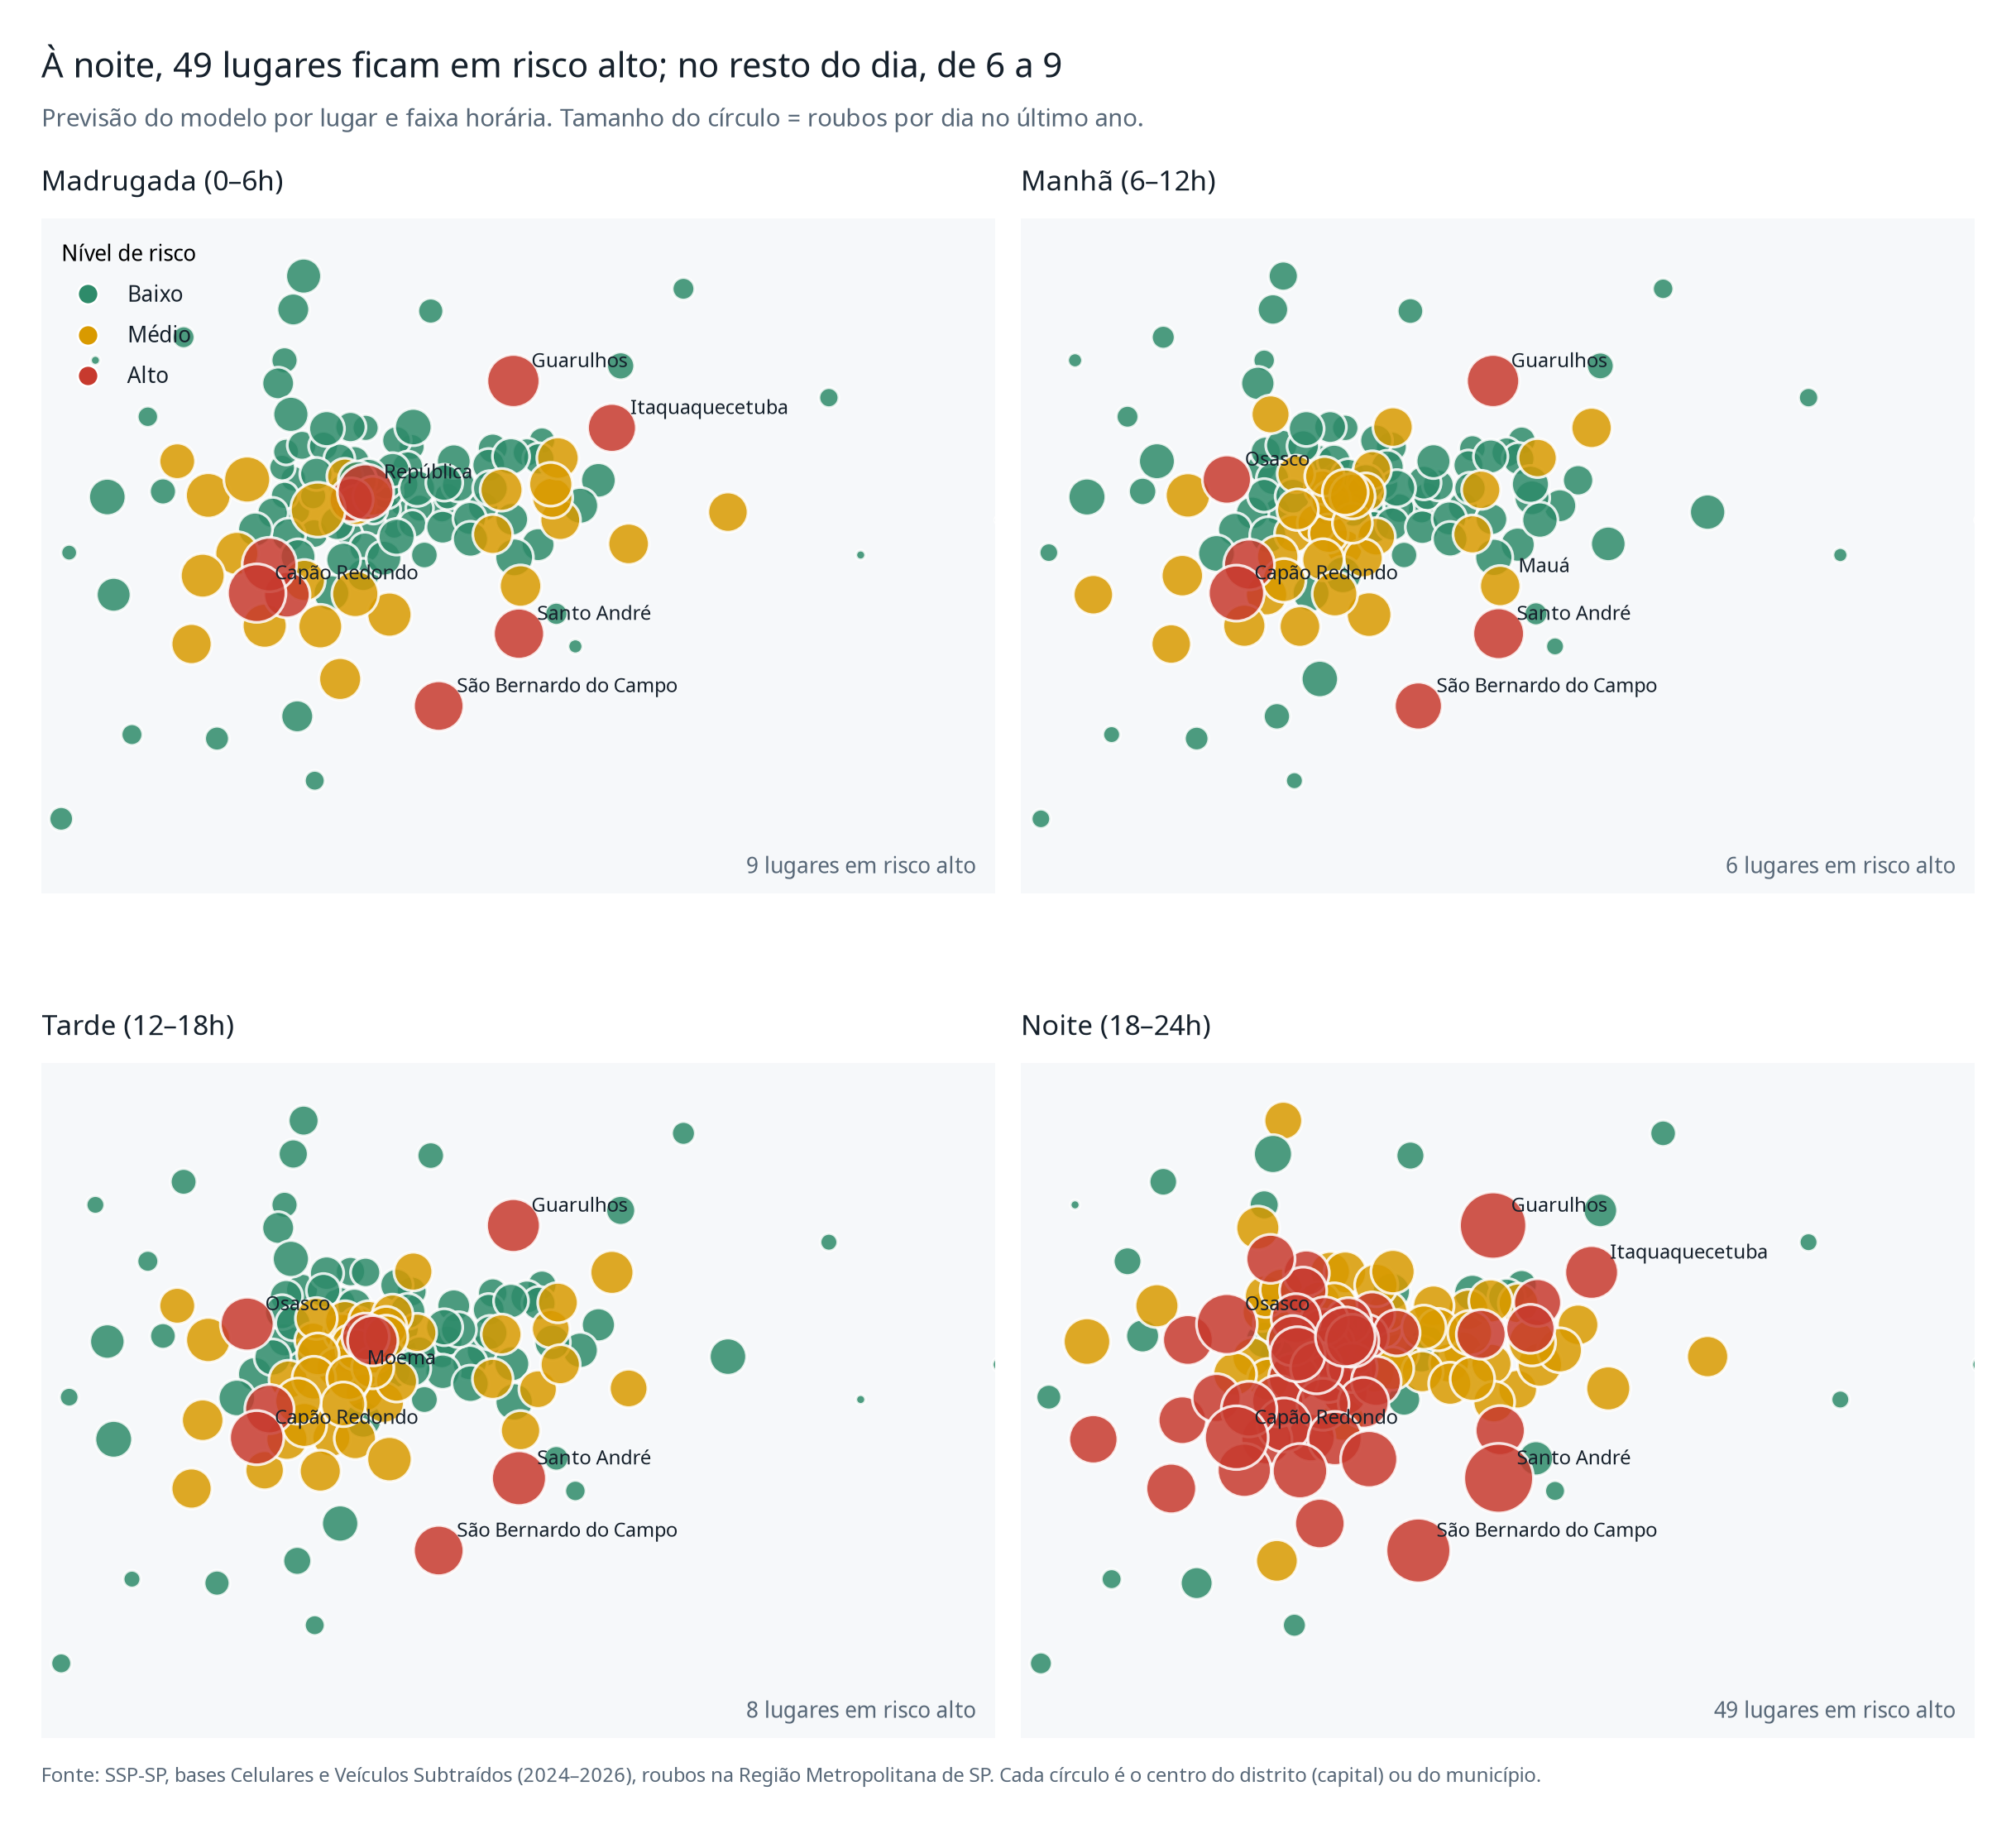

In [16]:
# roubos por dia de cada lugar × faixa nos últimos 12 meses (tamanho do círculo no mapa)
t12 = taxas(agregado, lugares, *j["final_x"])
dias = pd.date_range(*j["final_x"])
taxa_faixa = t12.groupby(["bairro", "faixa_horaria"]).roubos.sum().div(len(dias)).rename("taxa").reset_index()
prev_mapa = prev_df.merge(taxa_faixa, on=["bairro", "faixa_horaria"])
mostrar(figuras.mapa_risco(lugares, prev_mapa), "08_mapa_risco")

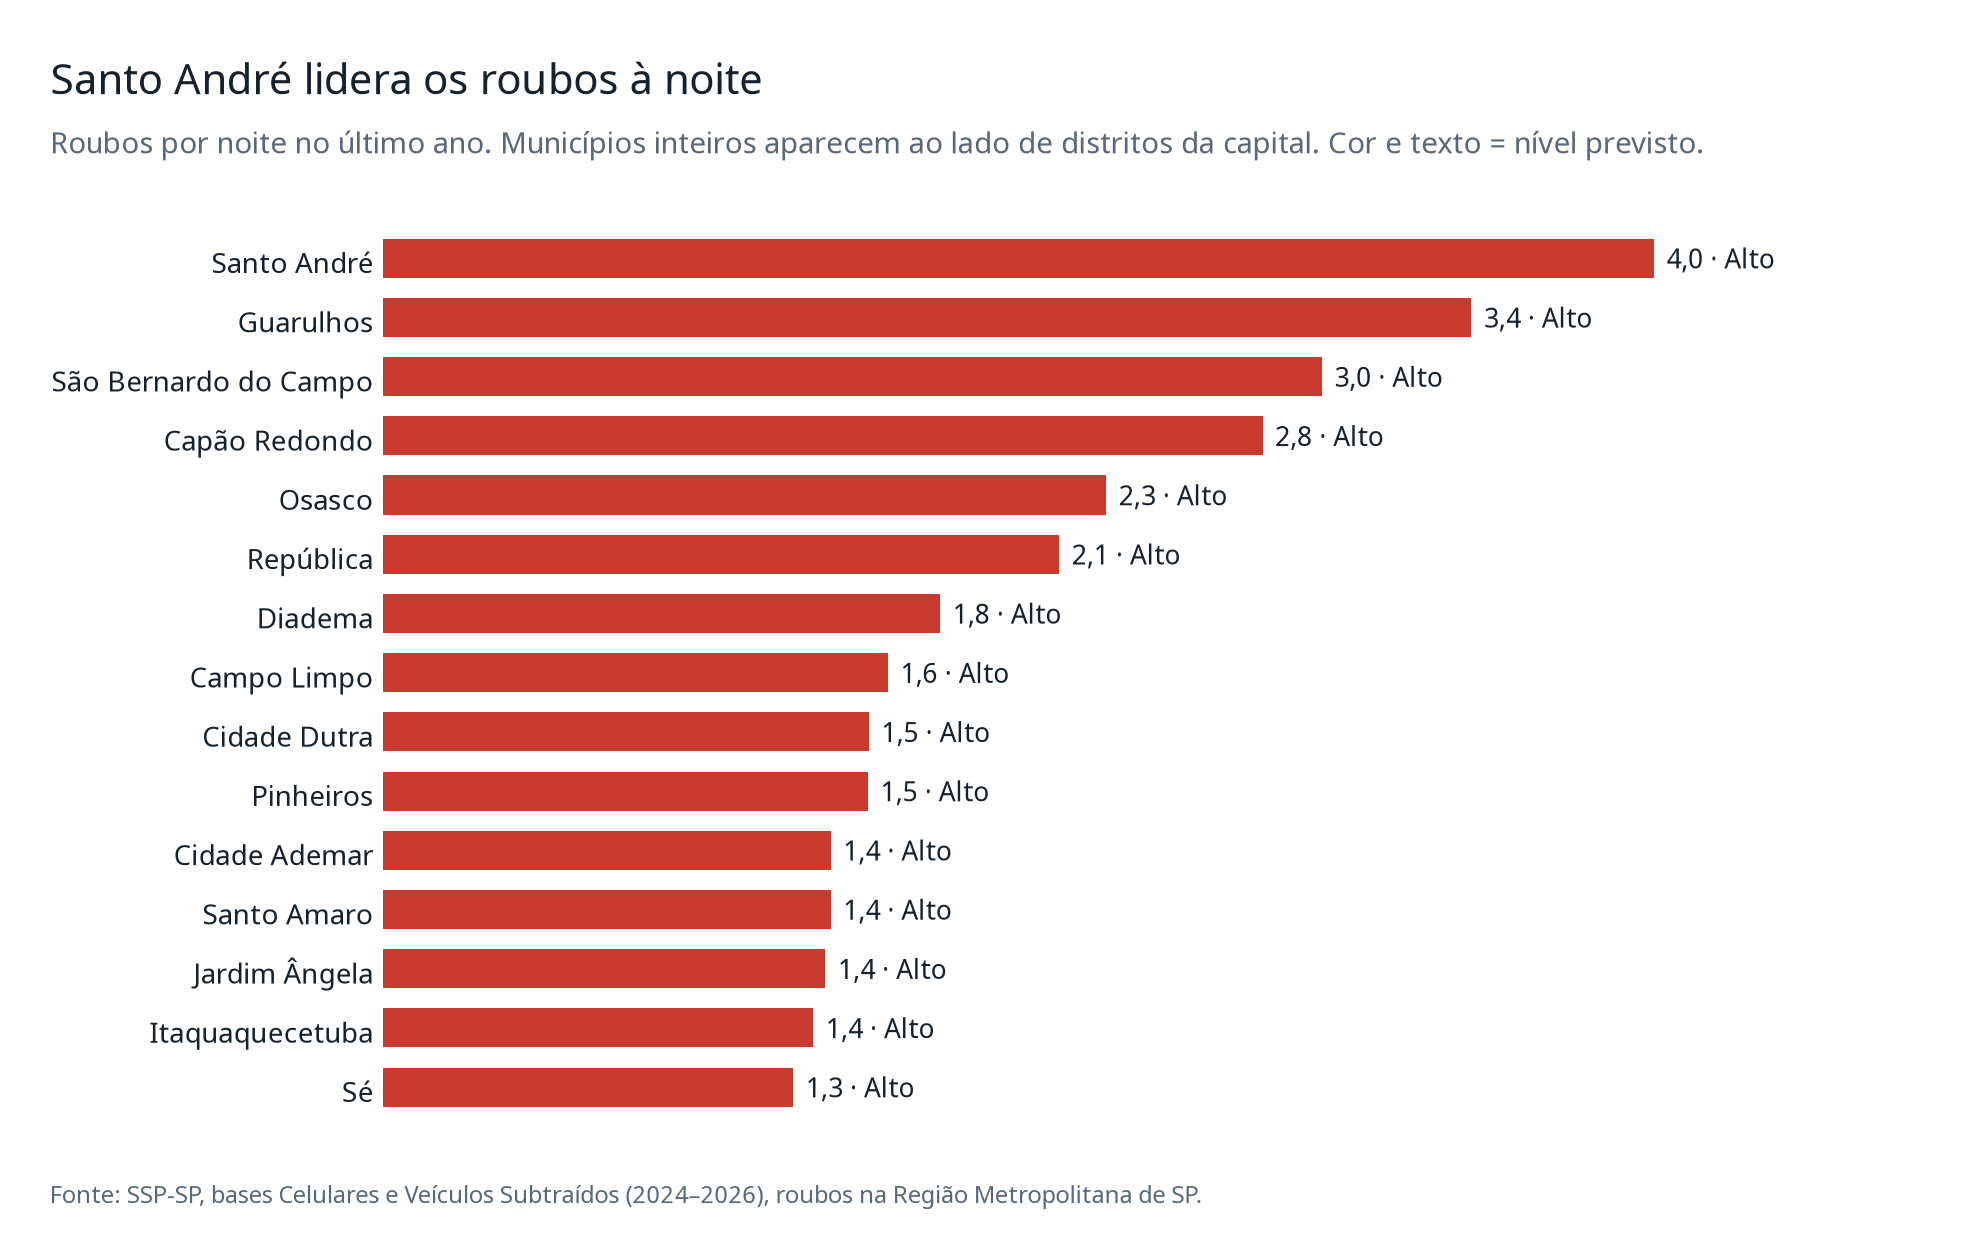

In [17]:
noite = prev_mapa[prev_mapa.faixa_horaria == "noite"].merge(lugares, left_on="bairro", right_on="codigo")
mostrar(figuras.ranking(noite[["nome", "taxa", "nivel_risco"]]), "09_ranking_noite")

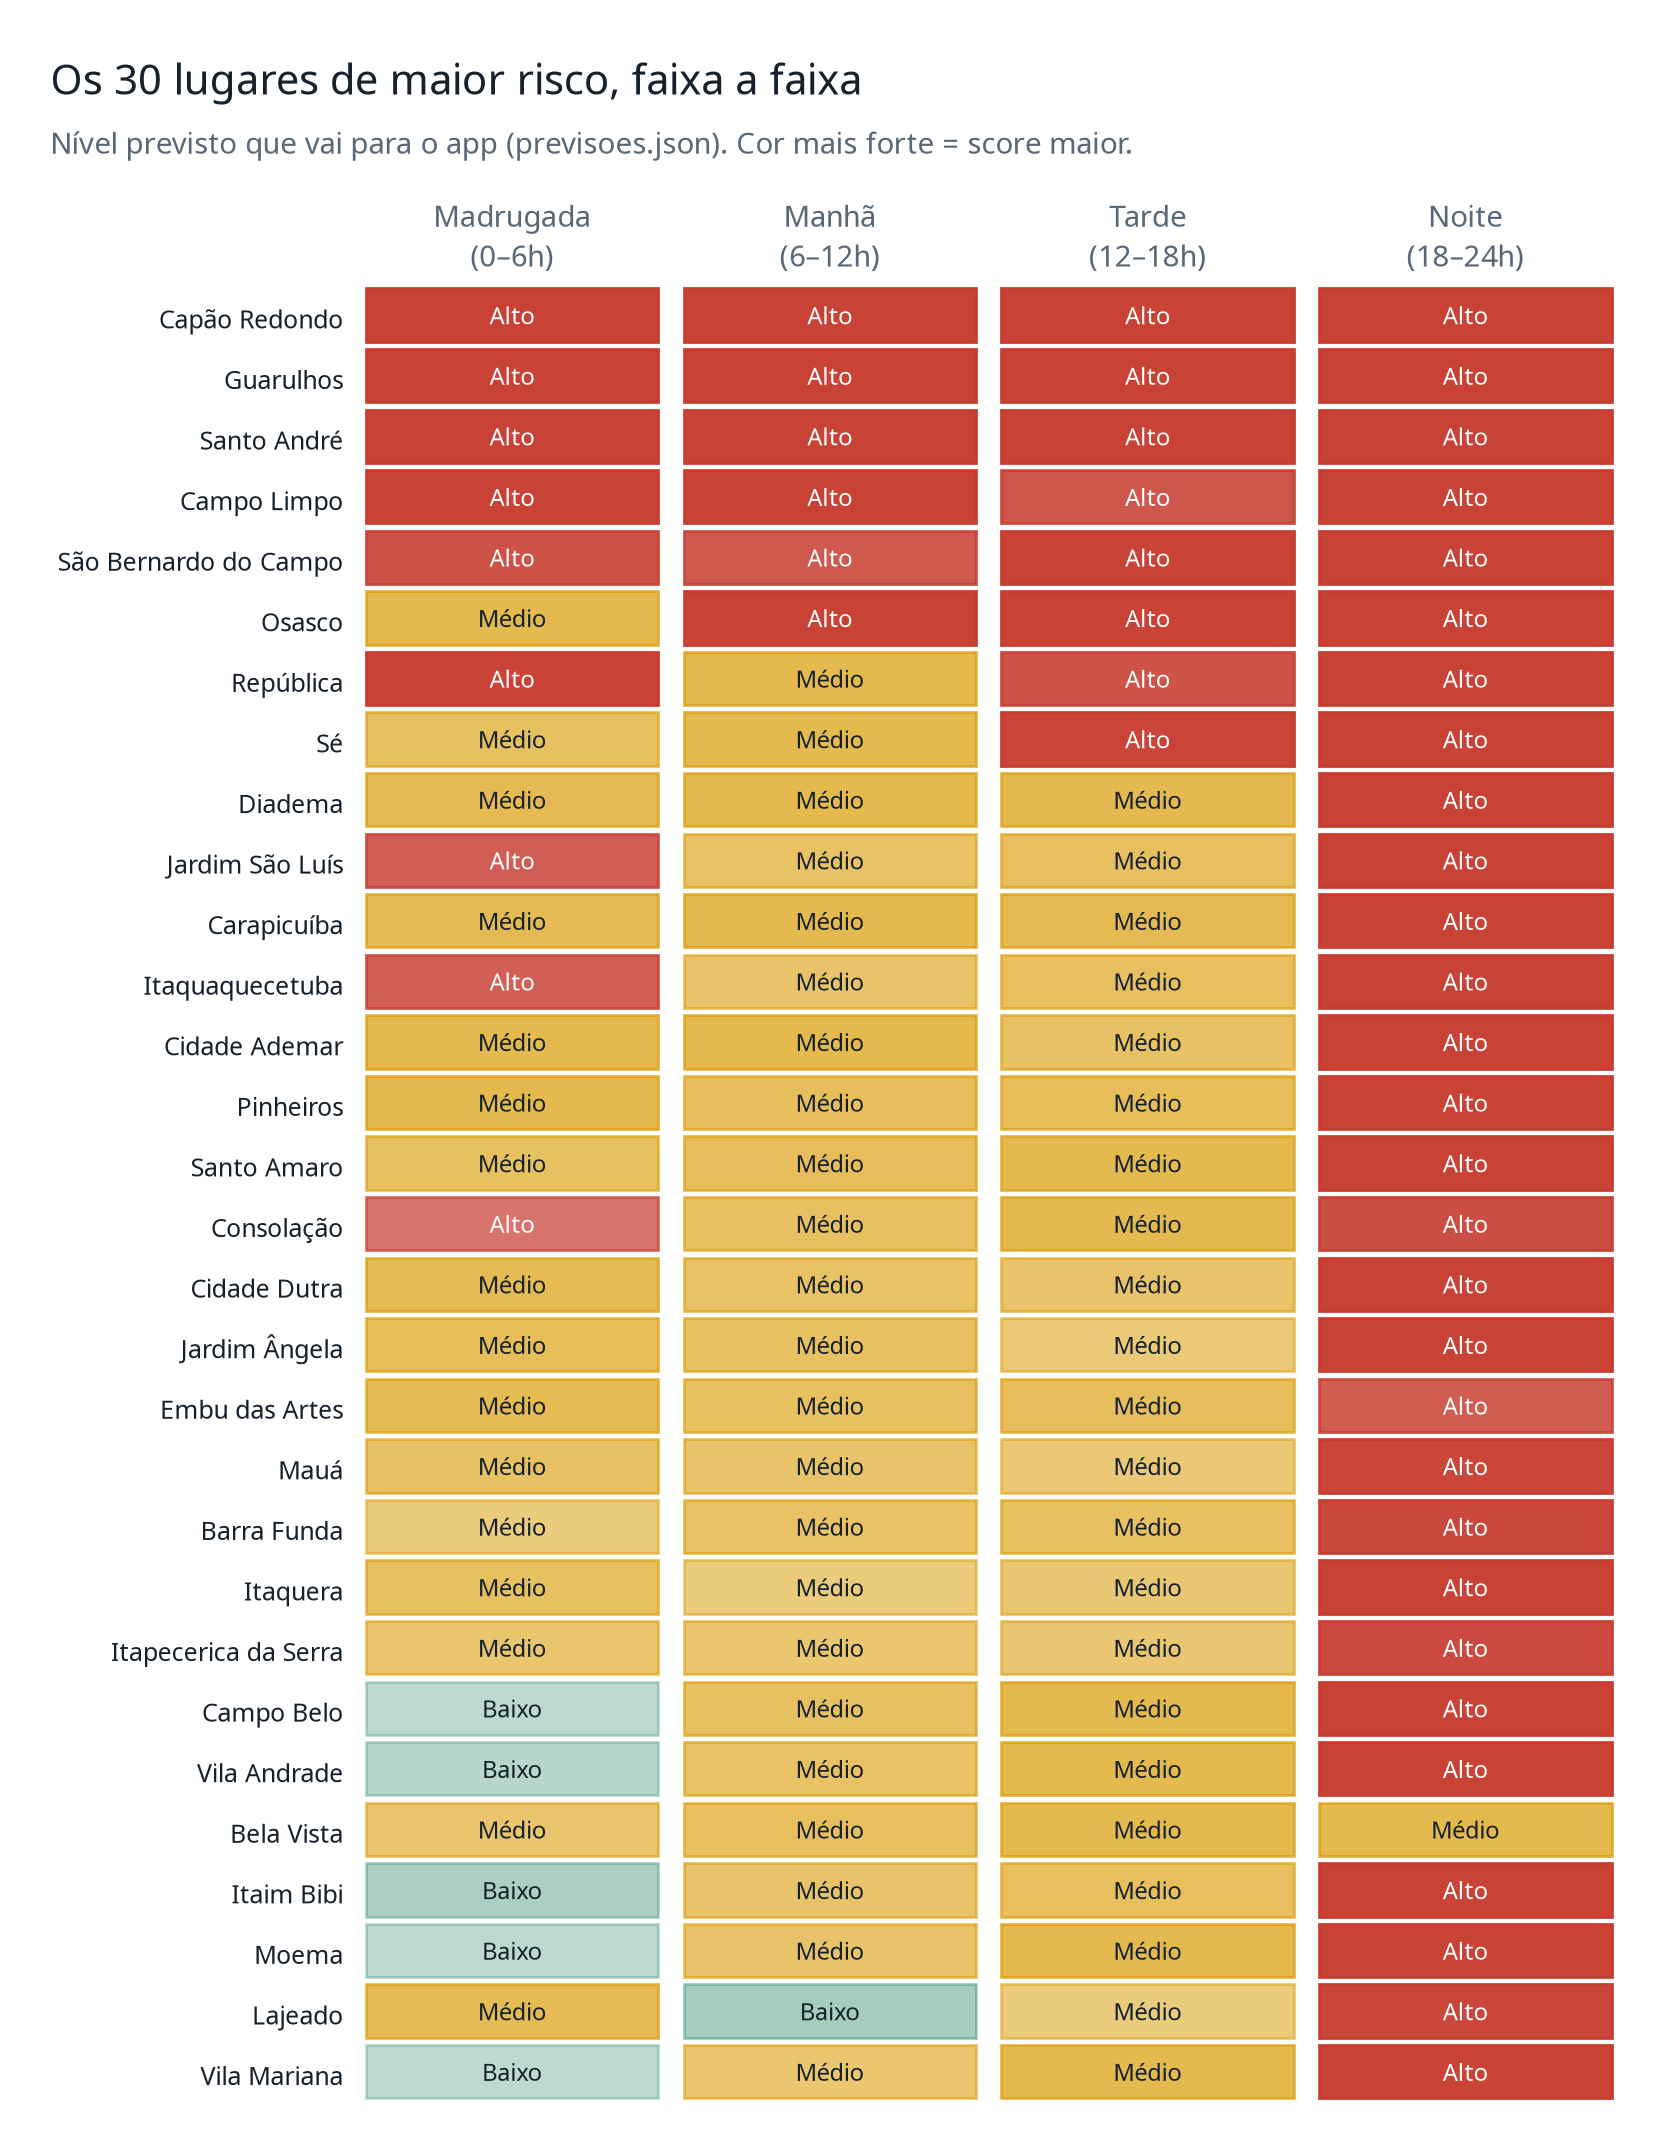

In [18]:
mostrar(figuras.grade_lugar_faixa(prev_df, lugares), "10_grade_lugar_faixa")

## 8. Previsão do mês corrente e o papel dos relatos

O nível da seção anterior é a **posição** de cada lugar entre os outros, e essa posição quase não muda: por isso
"repetir o nível do ano anterior" chega perto do modelo. A pergunta que a regra simples não responde é **quantos
roubos esperar** num mês que a SSP ainda não publicou.

- **Célula:** lugar × faixa horária (516). **Alvo:** roubos por dia no mês.
- **Atraso:** o modelo só vê o que já estaria publicado: para prever um mês, usa os dados até 3 meses antes.
- **Features:** último mês publicado, média de 3 e de 12 meses, tendência (3 meses ÷ 12 meses), faixa, distância
  até a Sé, município ou capital, e quantos meses à frente. O mesmo mês do ano anterior e o mês do ano foram
  testados e saíram: com só 2 anos e meio de dados e os roubos caindo, puxavam a previsão para cima (no total da
  região, o erro do teste subia de 482 para 601 roubos por mês).
- **Teste retroativo:** para cada mês de 2026, um RandomForest de regressão é treinado só com o que se sabia
  naquela época e prevê o mês. As referências são as regras simples.

In [19]:
from risco import mensal

t_mes = mensal.taxa_mensal(agregado, lugares, fim)
calibracao = list(pd.period_range("2025-07", "2025-12", freq="M"))
teste_mes = list(pd.period_range("2026-01", t_mes.columns[-1], freq="M"))
retro = mensal.teste_retroativo(t_mes, lugares, calibracao + teste_mes)
retro_cal, retro_teste = retro[retro.mes < "2026-01"], retro[retro.mes >= "2026-01"]
erros = mensal.erro_medio(retro_teste)
pd.Series(erros, name="erro médio (roubos por dia, por célula)").sort_values().to_frame()

,"erro médio (roubos por dia, por célula)"
modelo,0.127
media_3m,0.133
media_12m,0.138
ultimo_publicado,0.156
mesmo_mes_ano_passado,0.194


,erro médio do total da região (roubos por mês)
modelo,482.3
media_3m,531.1
ultimo_publicado,550.8
media_12m,733.3
mesmo_mes_ano_passado,1325.4


Erro médio do total da região no teste: 482 roubos por mês (7.7%)


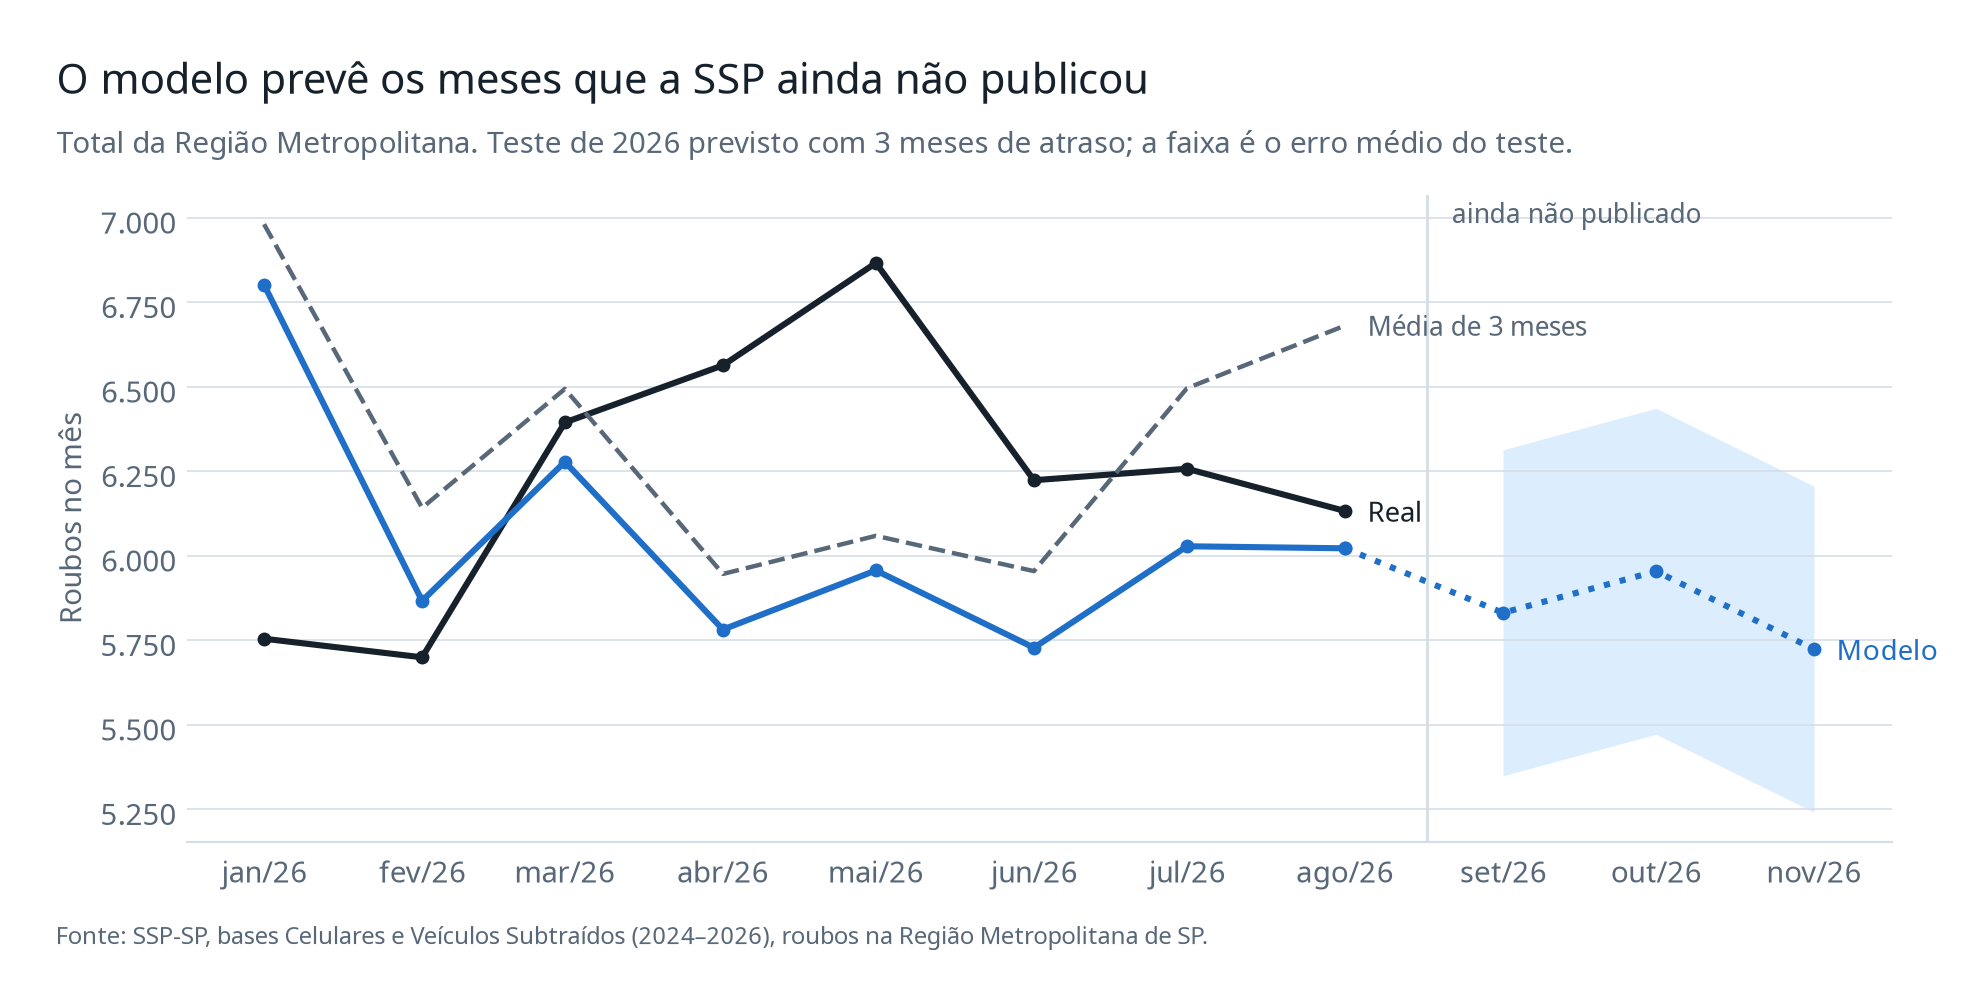

In [20]:
dias_mes = retro_teste.mes.map(lambda m: pd.Period(m).days_in_month)
regiao = (retro_teste.drop(columns="mes").mul(dias_mes, axis=0)
          .assign(mes=retro_teste.mes).groupby("mes").sum().reset_index())
erros_regiao = {c: round(float((regiao[c] - regiao.real).abs().mean()), 1) for c in regiao.columns if c not in ("mes", "real")}
erro_regiao = erros_regiao["modelo"]
display(pd.Series(erros_regiao, name="erro médio do total da região (roubos por mês)").sort_values().to_frame())
futuro_cel = mensal.prever_proximos(t_mes, lugares)
futuro = futuro_cel.groupby("mes").roubos.sum().reset_index()
print(f"Erro médio do total da região no teste: {erro_regiao:,.0f} roubos por mês ({erro_regiao / regiao.real.mean():.1%})")
mostrar(figuras.previsao_mensal(regiao, futuro, erro_regiao), "11_previsao_mensal")

**Os relatos.** Os relatos do app chegam na hora, mas só uma parte das vítimas vai relatar. Para medir o
efeito sem dados reais do app, cada roubo real de 2026 vira um relato com probabilidade igual à **adesão** (1% a
20%). A previsão e os relatos se juntam numa média gama-Poisson: a previsão vale um certo número de dias de
observação, escolhido nos meses de calibração (2º semestre de 2025), e os relatos valem os dias do mês.

,peso_dias,erro_modelo,erro_com_relatos,ganho
adesao,,,,
0.01,1280,0.127,0.126,0.010
0.02,640,0.127,0.124,0.028
0.05,160,0.127,0.120,0.056
0.10,80,0.127,0.113,0.113
0.20,40,0.127,0.103,0.193


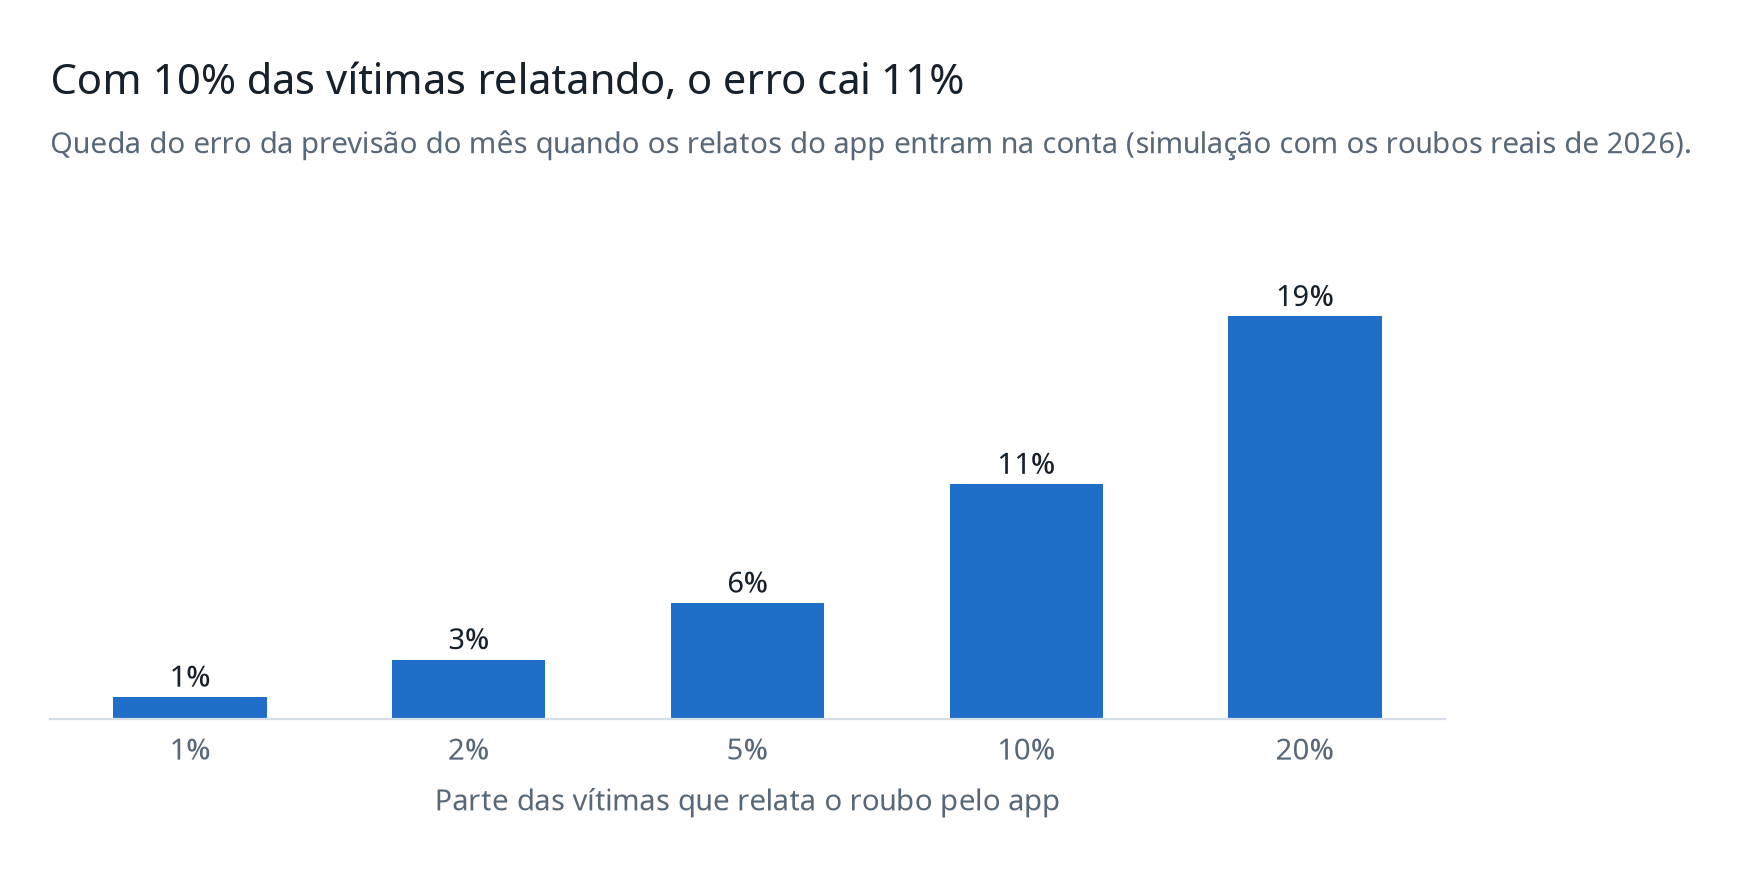

In [21]:
ganhos = mensal.avaliar_relatos(retro_cal, retro_teste)
display(pd.DataFrame(ganhos).set_index("adesao"))
mostrar(figuras.ganho_relatos(ganhos), "12_ganho_relatos")

In [22]:
historico = (t_mes * [m.days_in_month for m in t_mes.columns]).round().astype(int)
celulas = []
for (bairro, faixa), linha in historico.iterrows():
    f = futuro_cel.loc[(bairro, faixa)]
    celulas.append({"bairro": bairro, "faixa_horaria": faixa, "historico": linha.tolist(),
                    "previsto": f.roubos.round(1).tolist(), "min": f.roubos_min.astype(int).tolist(),
                    "max": f.roubos_max.astype(int).tolist()})
previsao_mensal = {
    "atraso_meses": mensal.ATRASO,
    "meses": [str(m) for m in t_mes.columns],
    "previstos": sorted(futuro_cel.mes.unique()),
    "teste": {"erro": erros, "regiao": regiao.round(1).to_dict("records"), "erro_regiao": erros_regiao},
    "relatos": ganhos,
    "celulas": celulas,
}
(DADOS / "previsao_mensal.json").write_text(json.dumps(previsao_mensal, ensure_ascii=False) + "\n")
print(f"previsao_mensal.json: {len(celulas)} células, meses previstos {previsao_mensal['previstos']}")

previsao_mensal.json: 516 células, meses previstos ['2026-09', '2026-10', '2026-11']


**Leitura.** Com 3 meses de atraso, o modelo erra menos que todas as regras simples, por célula e no total da
região, mas a vantagem sobre a média dos últimos 3 meses é pequena: o número de roubos de um lugar num mês é muito
aleatório. O ganho maior vem
dos relatos: quanto mais vítimas relatam pelo app, mais a previsão do mês corrente se aproxima do real. **É esse o
papel do morador na solução: cada relato melhora a previsão para todos.** A adesão real é desconhecida; os
números acima são uma simulação com os roubos reais.

## 9. Integração na solução

1. `data/previsoes.json` (516 linhas: 129 lugares × 4 faixas) é carregado pela **API (ASP.NET, João)** na primeira
   execução e servido em `GET /api/previsoes?bairro=`.
2. O **app (Expo)** usa essas previsões no mapa (cor de cada lugar), na faixa "Agora, à noite · Maior risco" e na
   aba **Risco**. O formato é o da seção 4 do `AGENTS.md`.
3. `data/relatos_simulados.csv` (10.000 relatos, gerado por `scripts/gerar_relatos.py`) alimenta a lista e o mapa de
   relatos. São simulados, mas sorteados na proporção dos roubos reais por lugar, faixa e dia da semana.
4. `data/previsao_mensal.json` (previsão do mês corrente por lugar e faixa, teste retroativo e efeito dos
   relatos) alimenta o site de resultados (`web/`).
5. Enquanto a API aceitar só os 3 bairros da Paulista, há os arquivos reserva `relatos_paulista.csv` e
   `previsoes_paulista.json`.

## 10. Limitações

- A base da SSP é **bruta** (sem padronização) e não é estatística oficial; ~7% dos roubos da capital não têm
  coordenada e ficaram fora.
- O distrito é aproximado pelo **centro mais próximo** (não usamos o contorno dos distritos).
- Os níveis são **relativos** à região (percentis), não um risco absoluto.
- Os roubos caíram de 2024 para 2026; com limites fixos, o teste tem mais células "baixo" que o treino.
- Os meses mais recentes ainda estão sendo preenchidos pela SSP (em set/2026, metade dos roubos de celular da
  capital ainda não tinha coordenada). Por isso o período vai até o último mês **completo** de todas as bases
  (regra em `fim_da_cobertura`, no `risco/ssp.py`).
- Dez/2024 tem metade dos roubos de veículo dos meses vizinhos, uma falha da própria base.
- Municípios inteiros (Guarulhos, Santo André…) são comparados com distritos da capital, que são menores.
- Roubos que a vítima não registrou não aparecem em nenhuma base.
- O efeito dos relatos é simulado com os roubos reais (cada roubo vira relato com uma probabilidade fixa). Relatos
  de verdade podem ter viés (lugares onde mais gente usa o app) e relatos falsos, por isso só os aprovados contam.